# 02 | Semantic Variance & Diversity Analysis (Live Demo)

**Objective:** Verify that our synthetic dataset covers diverse scenarios rather than repetitive LLM outputs.

**Methodology:**
* **GPU Embeddings:** Encodes transcripts into dense vectors on CUDA using `all-MiniLM-L6-v2`.
* **Cosine Similarity Matrix:** Computes pairwise similarity across all dialogues.
* **Diversity Threshold:** Mean similarity $< 0.65$ confirms high semantic variety.

## 1. GPU Embedding & Similarity Calculation

In [3]:
import torch
import torch.nn as nn
import sys
sys.modules['nn'] = nn

# Danach wie gewohnt:
import json
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics.pairwise import cosine_similarity
from sentence_transformers import SentenceTransformer

FILE_PATH = '/data/nemo-fraud-detection-notebooks/notebooks/01_Data_Generation/data/transcripts.jsonl'

def analyze_variance(file_path: str):
    print(f'Loading dataset from: {file_path}...')
    with open(file_path, 'r', encoding='utf-8') as f:
        texts = [json.loads(line)['text'] for line in f if line.strip()]

    print(f'✅ {len(texts)} dialogues loaded. Computing embeddings on NVIDIA GPU (CUDA)...')
    model = SentenceTransformer('all-MiniLM-L6-v2', device='cuda')
    embeddings = model.encode(texts, show_progress_bar=False, batch_size=64)

    sim_matrix = cosine_similarity(embeddings)
    np.fill_diagonal(sim_matrix, np.nan)

    avg_sim = np.nanmean(sim_matrix)
    max_sim = np.nanmax(sim_matrix)
    min_sim = np.nanmin(sim_matrix)

    print('\n' + '='*50)
    print('       SEMANTIC VARIANCE ANALYSIS RESULTS       ')
    print('='*50)
    print(f'Analyzed records           : {len(texts)}')
    print(f'Average similarity         : {avg_sim:.4f}  (Target < 0.65)')
    print(f'Highest similarity         : {max_sim:.4f}  (Duplicate risk > 0.95)')
    print(f'Lowest similarity          : {min_sim:.4f}  (Max scenario spread)')
    print('='*50)

    if avg_sim < 0.65:
        print('🌟 Result: Excellent semantic diversity across generated scenarios!')
    elif avg_sim < 0.80:
        print('👍 Result: Solid balance between domain focus and variety.')
    else:
        print('⚠️ Warning: High similarity detected. Increase prompt variance.')
        
    return sim_matrix

sim_matrix = analyze_variance(FILE_PATH)

Loading dataset from: /data/nemo-fraud-detection-notebooks/notebooks/01_Data_Generation/data/transcripts.jsonl...
✅ 93 dialogues loaded. Computing embeddings on NVIDIA GPU (CUDA)...


/usr/local/lib/python3.10/dist-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(



       SEMANTIC VARIANCE ANALYSIS RESULTS       
Analyzed records           : 93
Average similarity         : 0.5211  (Target < 0.65)
Highest similarity         : 0.9414  (Duplicate risk > 0.95)
Lowest similarity          : 0.1743  (Max scenario spread)
🌟 Result: Excellent semantic diversity across generated scenarios!


## 2. Pairwise Similarity Distribution
* **Left Tail (< 0.5):** Distinct banking topics and fraud patterns.
* **Right Tail (> 0.9):** Near-duplicates (subsequently removed by NeMo Curator).

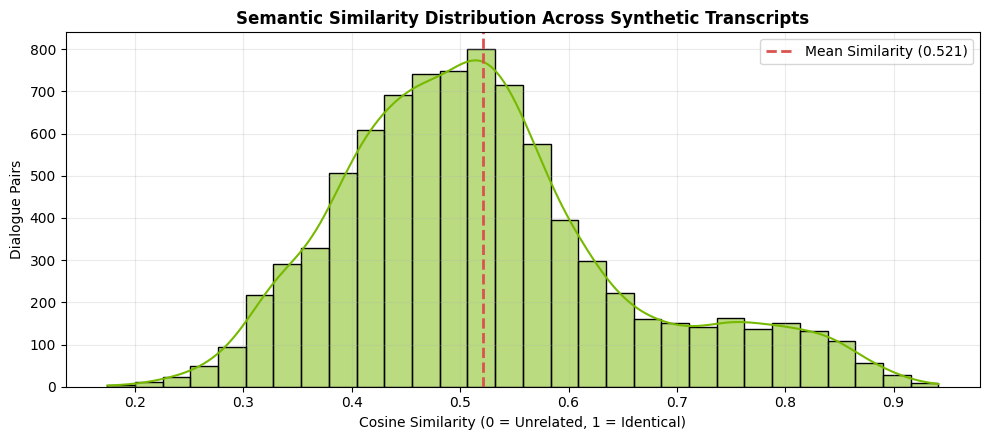

In [4]:
if sim_matrix is not None:
    flat_sims = sim_matrix[~np.isnan(sim_matrix)]

    plt.figure(figsize=(10, 4.5))
    sns.histplot(flat_sims, bins=30, kde=True, color='#76b900')  # NVIDIA Green
    plt.title('Semantic Similarity Distribution Across Synthetic Transcripts', fontsize=12, fontweight='bold')
    plt.xlabel('Cosine Similarity (0 = Unrelated, 1 = Identical)', fontsize=10)
    plt.ylabel('Dialogue Pairs', fontsize=10)
    plt.axvline(x=np.mean(flat_sims), color='#d9534f', linestyle='--', linewidth=2, label=f'Mean Similarity ({np.mean(flat_sims):.3f})')
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

### Key Takeaways
* **Automated Diversity Check:** Prevents model overfitting on repetitive synthetic phrasing.
* **GPU-Accelerated:** Scales effortlessly to tens of thousands of transcripts using CUDA.